Un profesor dă teste care pot fi dificile, medii sau uşoare. Probabilitatea dificultăţii primului test este aceeaşi. Dacă, la
un moment dat, dă un test dificil, următorul test poate fi doar mediu sau uşor, cu aceeaşi probabilitate. Însă dacă dă un
test mediu sau uşor, atunci următorul test va fi dificil cu probabilitate 0.5, sau mediu sau uşor cu aceeaşi probabilitate,
0.25.
Nota unui student la test, FB, B, S sau NS depinde de dificultatea testului. Astfel, probabilităţile condiţionate ale notei
obţinute, dată fiind dificultatea testului, sunt:
- test dificil: [0.1, 0.2, 0.4, 0.3];
- test mediu: [0.15, 0.25, 0.5, 0.1];
- test uşor: [0.2, 0.3, 0.4, 0.1].

a) Utilizaţi librăria hmmlearn pentru a defini modelul Markov ascuns şi desenaţi diagrama de stare.

b) Să presupunem că aţi observat următoarea secvenţă de note: FB, FB, S, B, B, S, B, B, NS, B, B, S. Determinaţi cea
mai probabilă secvenţă de dificultăţi pentru testele corespunzaătoare şi probabilitatea acesteia.

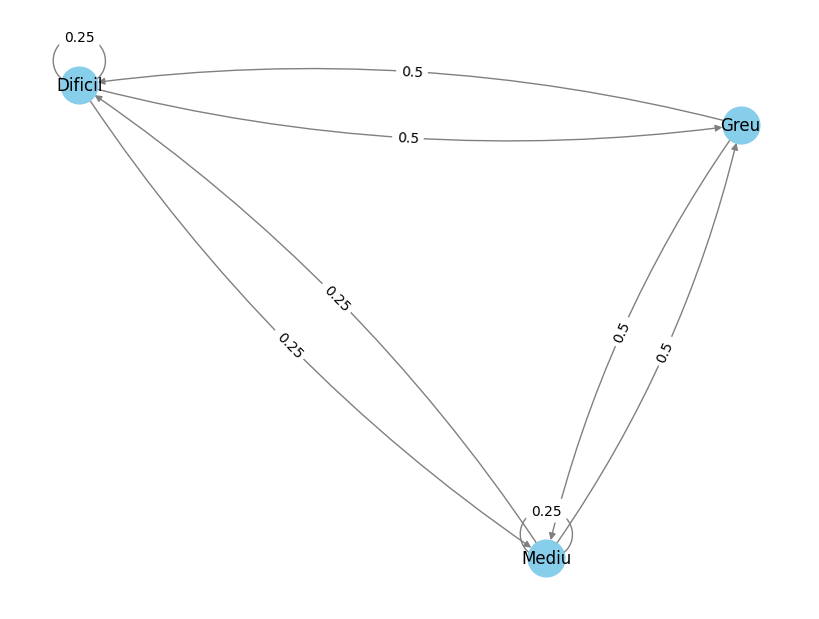

prob=2.109375000000024e-11
['Greu', 'Dificil', 'Greu', 'Dificil', 'Greu', 'Mediu', 'Greu', 'Dificil', 'Greu', 'Dificil', 'Greu', 'Mediu']


In [55]:
import matplotlib.pyplot as plt
import networkx as nx
from hmmlearn import hmm
import numpy as np

initial_prob = np.asarray([1/3, 1/3, 1/3], dtype=np.float64)
transition = np.asarray([
    [0.25,0.25,0.5],
    [0.25,0.25,0.5],
    [0.5,0.5,0.0],
], dtype=np.float64)
emission_prob = np.asarray([
    [0.2, 0.3, 0.4, 0.1],
    [0.15, 0.25, 0.5, 0.1],
    [0.1, 0.2, 0.4, 0.3]
], dtype=np.float64)

# a)

G = nx.DiGraph(arrows=True)
diffs = ["Dificil", "Mediu", "Greu"]
for diff in diffs:
    G.add_node(diff)

for i in range(len(diffs)):
    for j in range(len(diffs)):
        if transition[i][j] > 0:
            G.add_edge(diffs[i], diffs[j], weight=transition[i][j])

plt.figure(figsize=(8, 6))
pos = nx.spring_layout(G)
edge_labels = nx.get_edge_attributes(G, 'weight')
nx.draw(G, pos, with_labels=True, node_color='skyblue', edge_color='gray', node_size=700, connectionstyle="arc3,rad=0.1")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, connectionstyle="arc3,rad=0.1")
plt.show()

# b)
model = hmm.CategoricalHMM(n_iter=12, n_components=3)
model.transmat_=transition
model.emissionprob_=emission_prob
model.startprob_=initial_prob
prob, predictions=model.decode(np.asarray([[0], [0], [2], [1], [1], [2], [1], [1], [3], [1], [1], [2]]))
print(f"prob={np.exp(prob)}")
print([diffs[pred] for pred in predictions])